# FL-BENCH-004.1 — FedAvg baseline

*Epic EPIC-001 · story fl_bench_004 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Implement and validate FedAvg; sweep rounds/epochs/participation.

## 2. Scientific background
FedAvg averages local models weighted by data size [mcmahan2017].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does the implementation satisfy its validation identities?
- **RQ2.** How does it behave under IID vs non-IID data?

## 4. Hypotheses
- **H1.** Validation identities hold to numerical precision.

## 5. Mathematical formulation
w_{t+1} = Σ_k p_k w_k^{t+1}, p_k = n_k/Σ n_j; single client ⇒ local SGD.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_bench_004"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_bench_004


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`fl.py`, `stats.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
parts = partition_dirichlet(data.y_train, 8, 0.3, SEED)
r = run_fl(FLConfig(algo="fedavg", rounds=6, local_epochs=2, mu=0.05, seed=SEED), data, parts)
print("fedavg final", {k: round(v, 4) for k, v in r.final.items() if isinstance(v, float)}, "comm MB", round(r.totals["comm_mb"], 3))
assert np.isfinite(r.w).all()

fedavg final {'round_time_s': 0.0637, 'agg_time_s': 0.0002, 'client_time_s': 0.0635, 'client_time_max_s': 0.0284, 'acc': 0.7911, 'loss': 0.4412, 'precision': 0.8165, 'recall': 0.6172, 'f1': 0.703, 'specificity': 0.9073, 'auc': 0.8767, 'diverged': 0.0} comm MB 0.505


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-BENCH-004.1` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_4_1_runs.csv')
show_csv('task_4_1_sweeps.csv')

,algo,condition,clients,seed,local_epochs,participation,mu,rounds,acc,precision,recall,f1,auc,loss,specificity,rounds_to_target,comm_mb,comm_mb_per_round,train_wall_s,cpu_time_s,rss_peak_mb,skew,pr_auc,ece
0,fedavg,iid,10,0,2,1.0,0.0,30,0.9050,0.8973,0.8626,0.8796,0.9653,0.2353,0.9336,11.0,3.154,0.1051,7.4725,7.39,716.1758,0.0149,0.9512,0.0194
1,fedavg,iid,10,1,2,1.0,0.0,30,0.9108,0.9022,0.8729,0.8873,0.9641,0.2384,0.9363,11.0,3.154,0.1051,7.3518,7.30,716.2109,0.0070,0.9499,0.0208
2,fedavg,iid,10,2,2,1.0,0.0,30,0.9094,0.9089,0.8612,0.8844,0.9655,0.2355,0.9419,12.0,3.154,0.1051,7.4646,7.43,716.2383,0.0170,0.9529,0.0262
3,fedavg,iid,10,3,2,1.0,0.0,30,0.9108,0.9116,0.8619,0.8860,0.9639,0.2405,0.9438,12.0,3.154,0.1051,7.4294,7.36,716.2695,0.0127,0.9487,0.0214
4,fedavg,iid,10,4,2,1.0,0.0,30,0.9081,0.9056,0.8612,0.8828,0.9646,0.2380,0.9396,13.0,3.154,0.1051,7.1245,7.08,716.2695,0.0142,0.9502,0.0236
5,fedavg,dir0.3,10,0,2,1.0,0.0,30,0.8897,0.9089,0.8066,0.8547,0.9561,0.2683,0.9456,13.0,3.154,0.1051,6.9764,6.95,716.4922,0.3296,0.9396,0.0303
6,fedavg,dir0.3,10,1,2,1.0,0.0,30,0.9019,0.9083,0.8412,0.8734,0.9615,0.2573,0.9428,7.0,3.154,0.1051,7.5730,7.49,716.5664,0.4088,0.9440,0.0294
7,fedavg,dir0.3,10,2,2,1.0,0.0,30,0.8497,0.9242,0.6823,0.7851,0.9405,0.3447,0.9624,NaN,3.154,0.1051,7.2165,7.16,716.5781,0.4206,0.9187,0.0852
8,fedavg,dir0.3,10,3,2,1.0,0.0,30,0.8461,0.9391,0.6602,0.7753,0.9399,0.3523,0.9712,NaN,3.154,0.1051,7.4785,7.41,716.5859,0.3944,0.9204,0.0937
9,fedavg,dir0.3,10,4,2,1.0,0.0,30,0.8994,0.9177,0.8239,0.8683,0.9606,0.2560,0.9503,12.0,3.154,0.1051,7.6453,7.53,716.5938,0.3500,0.9440,0.0296


,factor,value,seed,acc,f1,rounds_to_target,comm_mb
0,participation,0.2,0,0.8403,0.7623,21.0,0.6308
1,participation,0.2,1,0.7869,0.7858,8.0,0.6308
2,participation,0.2,2,0.8425,0.7716,21.0,0.6308
3,participation,0.5,0,0.8867,0.8488,15.0,1.5770
4,participation,0.5,1,0.8714,0.8547,6.0,1.5770
5,participation,0.5,2,0.6744,0.3218,28.0,1.5770
6,participation,1.0,0,0.8897,0.8547,13.0,3.1540
7,participation,1.0,1,0.9019,0.8734,7.0,3.1540
8,participation,1.0,2,0.8497,0.7851,NaN,3.1540
9,local_epochs,1.0,0,0.8736,0.8307,21.0,3.1540


## 12. Metrics collection
Metric definitions: accuracy, F1, rounds-to-target (acc≥0.85), logical communication MB, local drift ||w_k − w_t||.

In [8]:
show_csv('task_4_1_summary.csv')

,condition,skew,acc,acc_ci,f1,f1_ci,loss,loss_ci,comm_mb,comm_mb_ci
0,iid,0.0132,0.9088,"[0.9058, 0.9119]",0.8840,"[0.8803, 0.8878]",0.2375,"[0.2349, 0.2402]",3.154,"[3.1540, 3.1540]"
1,dir0.3,0.3807,0.8774,"[0.8435, 0.9113]",0.8314,"[0.7726, 0.8901]",0.2957,"[0.2355, 0.3560]",3.154,"[3.1540, 3.1540]"


## 13. Statistical analysis
Seeds are the unit of replication; paired tests across seeds (Wilcoxon signed-rank, paired t), Holm correction, Cohen's d_z; see task 4.6.

In [9]:
show_csv('task_4_1_summary.csv', 30)

,condition,skew,acc,acc_ci,f1,f1_ci,loss,loss_ci,comm_mb,comm_mb_ci
0,iid,0.0132,0.9088,"[0.9058, 0.9119]",0.8840,"[0.8803, 0.8878]",0.2375,"[0.2349, 0.2402]",3.154,"[3.1540, 3.1540]"
1,dir0.3,0.3807,0.8774,"[0.8435, 0.9113]",0.8314,"[0.7726, 0.8901]",0.2957,"[0.2355, 0.3560]",3.154,"[3.1540, 3.1540]"


## 14. Visualizations

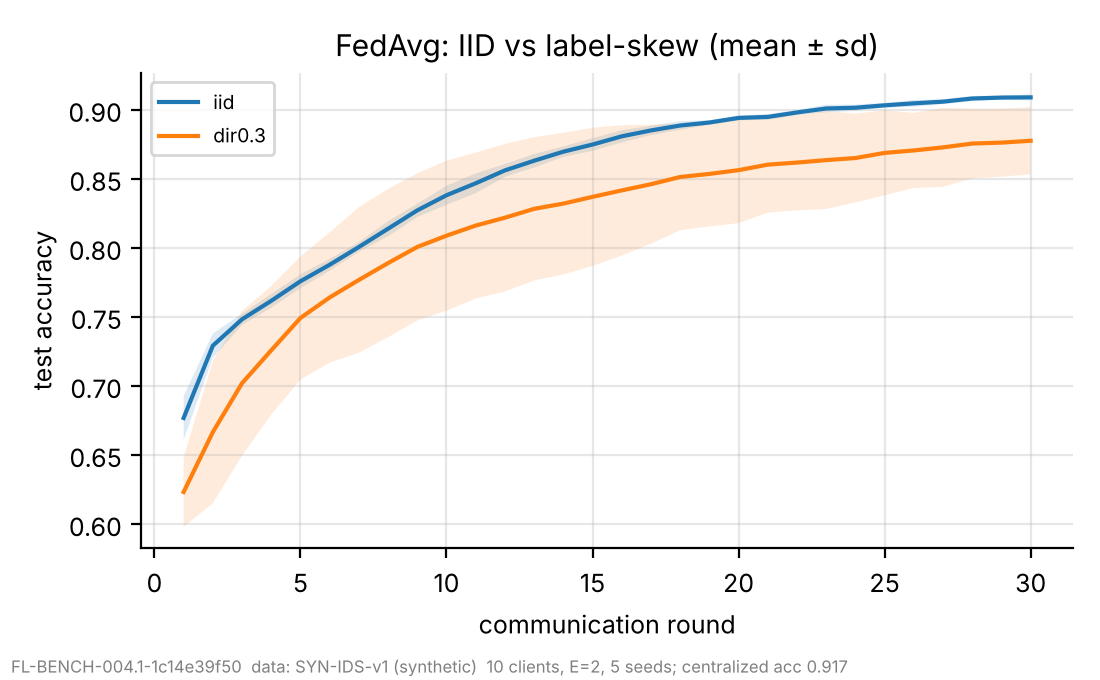

In [10]:
show_fig('task_4_1_fedavg.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

See printed summary.

In [11]:
J = json.load(open(RES / 'task_4_1_fedavg.json')); print([k for k in J if k != 'provenance'])

['validation', 'summary', 'sweeps', 'centralized_reference', 'curves']


## 16. Limitations
- Synthetic tabular data; small MLP.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Implementation validated by identity tests (tests/ and task JSON).

**Jira acceptance:** see `docs/fl_bench_004/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`mcmahan2017`, `li2020fedprox`, `karimireddy2020`, `wang2020fednova`, `li2021niid` — details in `docs/fl_bench_004/references.md`.